In [3]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
import random
import torchvision.transforms.functional as F

In [4]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

Using device: cuda


In [5]:
img_type = "annotations"

In [6]:
batch_size = 512
learning_rate = 3e-4
n_epochs = 10
n_classes = 5
crop_size = 32

In [7]:
def random_90_rotation(img):
    angles = [0, 90, 180, 270]
    return F.rotate(img, angle=random.choice(angles))

transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = datasets.ImageFolder(root=f"data/dataset_crops_{img_type}/train", transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=6)

val_dataset = datasets.ImageFolder(root=f"data/dataset_crops_{img_type}/val", transform=transform)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=6)

# test_dataset = datasets.ImageFolder(root=f"data/dataset_crops_{img_type}/test", transform=transform)
# test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=1)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)
# test_iterator = iter(test_loader)

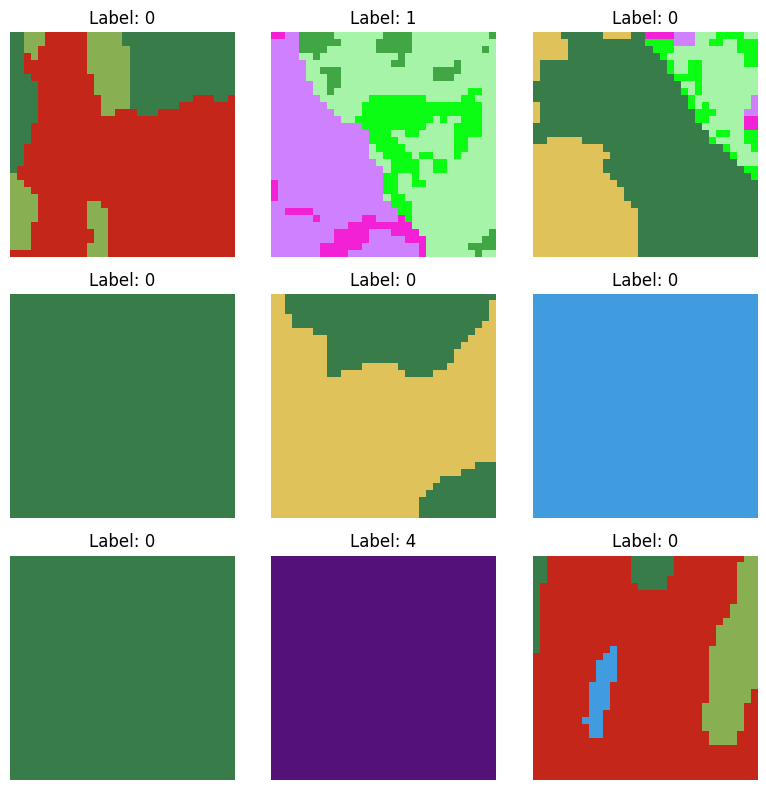

In [8]:
# Afficher une grille 3x3 d'exemples
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i in range(3):
    for j in range(3):
        img, label = next(train_iterator)
        axes[i, j].imshow((img[0].permute(1, 2, 0).numpy() + 1)/2)
        axes[i, j].set_title(f"Label: {label[0]}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [9]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

# Charger un modèle préentraîné
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
# model = resnet18(weights=None)

# # différentes couches du modèle
# for name, layer in model.named_children():
#     print(name, ":", layer)

# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, n_classes)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params/1e6:.6f} million")

Total parameters in the model: 11.179077 million


In [10]:
model = model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

train_loss_list, val_loss_list, test_loss_list = [], [], []
train_acc_list, val_acc_list, test_acc_list = [], [], []

In [11]:
def get_accuracy(split, iterator):
    if split == "train":
        loader = train_loader
    elif split == "val":
        loader = val_loader
    # elif split == "test":
    #     loader = test_loader
    else:
        print("split non définit")
        return None

    model.eval()
    with torch.no_grad():
        try:
            x, y = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            x, y = next(iterator)
        x, y = x.to(device), y.to(device)
        y_hat = model(x)
        probs = torch.softmax(y_hat, dim=1)
        preds = torch.argmax(probs, dim=1)
        n_correct = (preds.view(-1) == y.view(-1)).float().sum().item()
        n_total = y.shape[0]
    accuracy = n_correct / n_total
    model.train()
    return accuracy, iterator

In [12]:
def moving_average(x, w=10):
    smoothed = []
    for i in range(len(x)):
        start = max(0, i - w + 1)
        window = x[start:i+1]
        smoothed.append(sum(window) / len(window))
    return smoothed

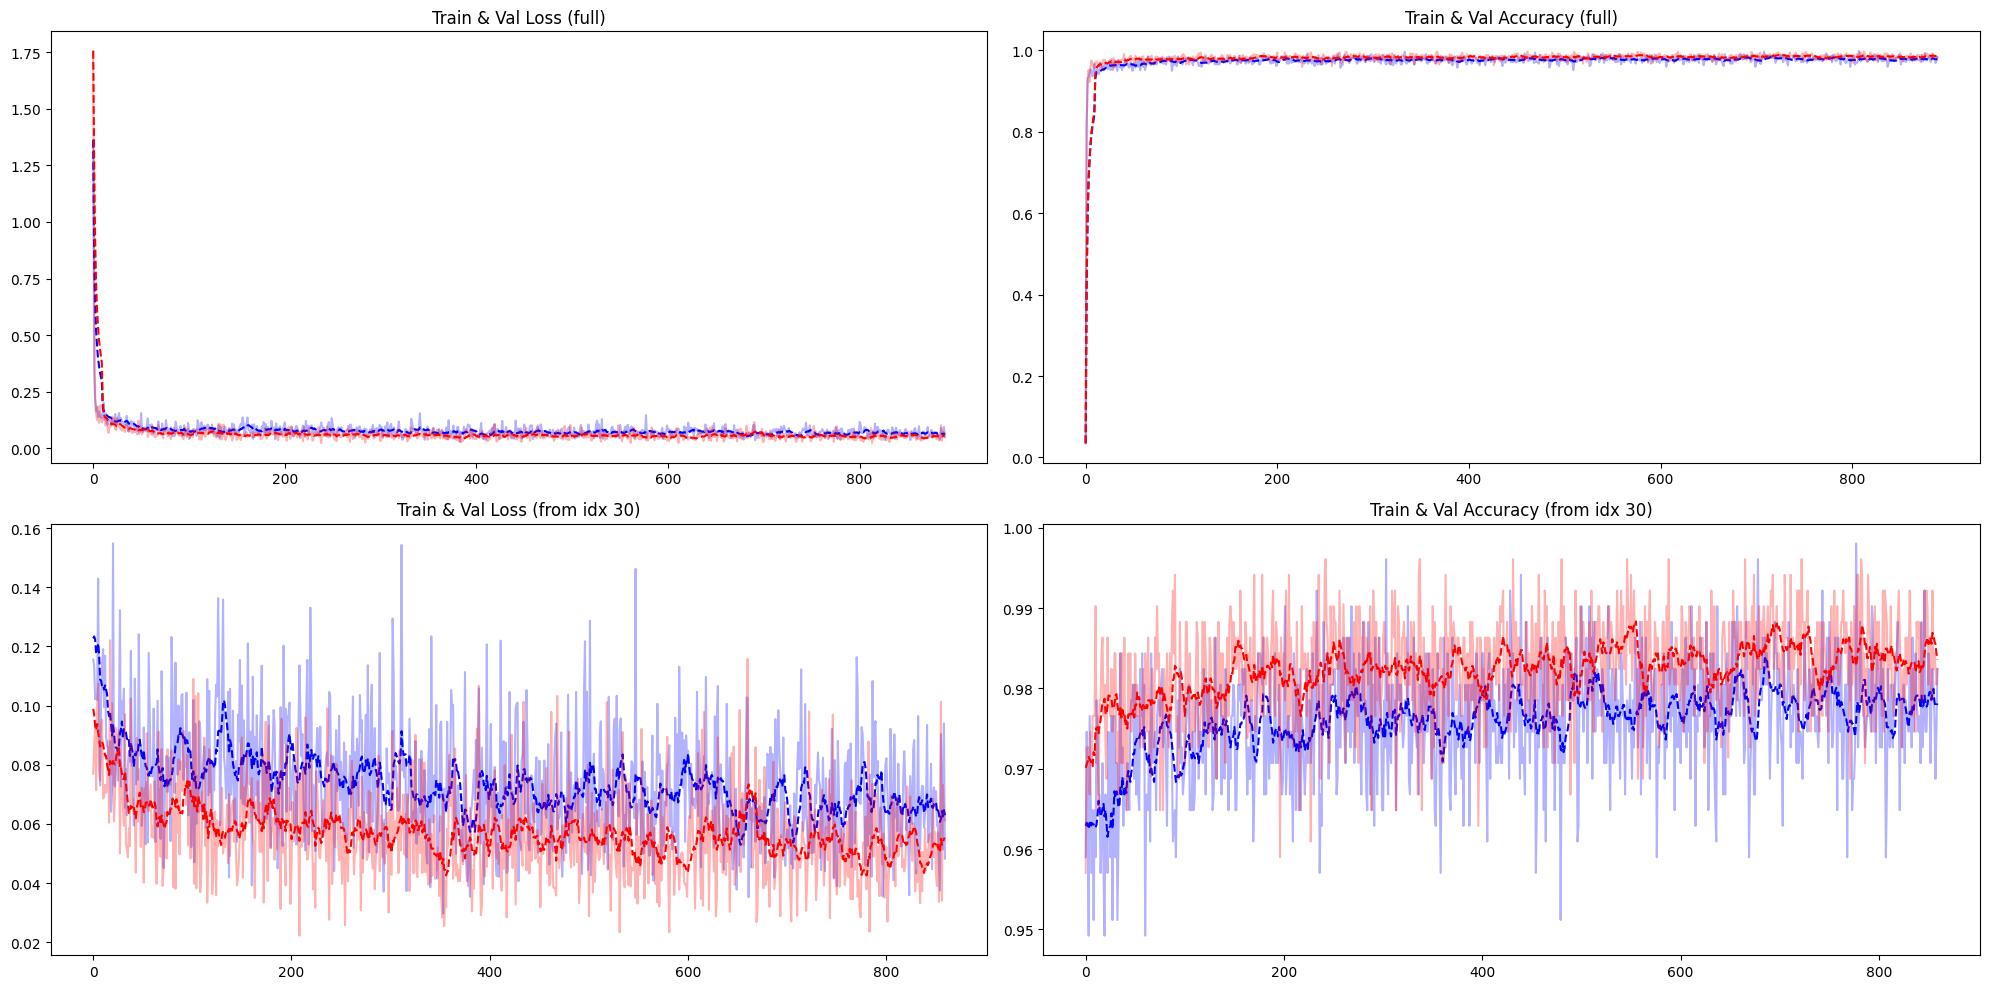

In [13]:
for epoch in range(n_epochs):
    for i, (imgs, classes) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, classes = imgs.to(device), classes.to(device)

        # imgs = torch.randn_like(imgs, device=device)

        output = model(imgs)
        loss = criterion(output, classes)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()



        if i % 10 == 0:
            train_loss_list.append(loss.item())

            # get val loss
            model.eval()
            with torch.no_grad():
                try:
                    imgs, classes = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, classes = next(val_iterator)
                imgs, classes = imgs.to(device), classes.to(device)
                output = model(imgs)
                val_loss = criterion(output, classes)
                val_loss_list.append(val_loss.item())
            model.train()

            # get accuracy
            train_acc, train_iterator = get_accuracy("train", train_iterator)
            val_acc, val_iterator = get_accuracy("val", val_iterator)
            train_acc_list.append(train_acc)
            val_acc_list.append(val_acc)


    train_loss_list_smoothed = moving_average(train_loss_list)
    val_loss_list_smoothed = moving_average(val_loss_list)
    train_acc_list_smoothed = moving_average(train_acc_list)
    val_acc_list_smoothed = moving_average(val_acc_list)

    clear_output(wait=True)  # efface l'ancien plot
    plt.figure(figsize=(20, 10))  # plus grand pour 4 sous-plots

    # 1er plot (train+val loss, full)
    plt.subplot(2, 2, 1)
    plt.plot(train_loss_list, c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
    plt.plot(val_loss_list, c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
    plt.title("Train & Val Loss (full)")

    # 2e plot (train+val acc, full)
    plt.subplot(2, 2, 2)
    plt.plot(train_acc_list, c="blue", alpha=0.3)
    plt.plot(train_acc_list_smoothed, c="blue", linestyle='--')
    plt.plot(val_acc_list, c="red", alpha=0.3)
    plt.plot(val_acc_list_smoothed, c="red", linestyle='--')
    plt.title("Train & Val Accuracy (full)")

    # 3e plot (train+val loss, from index 30)
    plt.subplot(2, 2, 3)
    plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
    plt.plot(val_loss_list[30:], c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
    plt.title("Train & Val Loss (from idx 30)")

    # 4e plot (train+val acc, from index 30)
    plt.subplot(2, 2, 4)
    plt.plot(train_acc_list[30:], c="blue", alpha=0.3)
    plt.plot(train_acc_list_smoothed[30:], c="blue", linestyle='--')
    plt.plot(val_acc_list[30:], c="red", alpha=0.3)
    plt.plot(val_acc_list_smoothed[30:], c="red", linestyle='--')
    plt.title("Train & Val Accuracy (from idx 30)")

    plt.tight_layout()  # ajuste l'espacement
    plt.show()


In [15]:
# sauvegarder les poids du modèle et les paramètres d'entraînement

torch.save({
    'epoch': epoch+1,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': train_loss_list_smoothed[-1],
}, f"weights/resnet_sur_crops_{img_type}_checkpoint10.pth")